In [1]:
import os
from pathlib import Path
import kagglehub

shords_path = kagglehub.dataset_download("mehanat96/major-vs-minor-guitar-chords")
audio_files_path = kagglehub.dataset_download("deepcontractor/musical-instrument-chord-classification")

print(f"shords_dataset: {shords_path}")
print(f"Audio_Files: {audio_files_path}")

data_dir = Path('data')
shords_dest = data_dir / 'shords_dataset'
audio_dest  = data_dir / 'Audio_Files'

if not shords_dest.exists():
    shords_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(shords_path, str(shords_dest))

if not audio_dest.exists():
    audio_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(audio_files_path, str(audio_dest))

Using Colab cache for faster access to the 'major-vs-minor-guitar-chords' dataset.
Using Colab cache for faster access to the 'musical-instrument-chord-classification' dataset.
shords_dataset: /kaggle/input/major-vs-minor-guitar-chords
Audio_Files: /kaggle/input/musical-instrument-chord-classification


In [2]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
import keras

from features import load_audio, extract_mel_spectrogram, extract_windowed_features
from models import get_sklearn_model, build_mlp, build_cnn, build_rnn, default_keras_callbacks

import warnings
warnings.filterwarnings('ignore')

### Save some files aside so that the algorithm can be tested manually later on unseen data

In [ ]:
import shutil
import random

AUDIO_EXTENSIONS = ['.wav', '.mp3']
MANUAL_TEST_DIR = Path('../data/manual_test')
N_PER_CLASS = 3

random.seed(42)

data_dirs = [
    Path('/content/data/Audio_Files/Audio_Files'),
    Path('/content/data/shords_dataset/shords_dataset')
]

files_by_class = {}
for data_dir in data_dirs:
    for label_dir in sorted(data_dir.iterdir()):
        if not label_dir.is_dir():
            continue
        label = label_dir.name.capitalize()
        files_by_class.setdefault(label, [])
        files_by_class[label].extend(
            f for f in sorted(label_dir.iterdir()) if f.suffix in AUDIO_EXTENSIONS
        )

held_out = set()
for label, files in files_by_class.items():
    selected = random.sample(files, min(N_PER_CLASS, len(files)))
    out_dir = MANUAL_TEST_DIR / label
    out_dir.mkdir(parents=True, exist_ok=True)
    for f in selected:
        shutil.copy2(f, out_dir / f.name)
        held_out.add(f.resolve())

print(f"Held out {len(held_out)} files for manual testing in {MANUAL_TEST_DIR}")
for label in sorted(files_by_class):
    count = sum(1 for f in held_out if f.parent.name.capitalize() == label)
    print(f"  {label}: {count}")

Held out 6 files for manual testing in ../data/manual_test
  Major: 3
  Minor: 3


In [17]:
!zip -r /data/manual.zip /data/manual_test

  adding: data/manual_test/ (stored 0%)
  adding: data/manual_test/Minor/ (stored 0%)
  adding: data/manual_test/Minor/Minor_324.wav (deflated 8%)
  adding: data/manual_test/Minor/Minor_352.wav (deflated 9%)
  adding: data/manual_test/Minor/Minor_304.wav (deflated 7%)
  adding: data/manual_test/Major/ (stored 0%)
  adding: data/manual_test/Major/6_8.wav (deflated 8%)
  adding: data/manual_test/Major/Major_120.wav (deflated 8%)
  adding: data/manual_test/Major/Major_200.wav (deflated 8%)


In [19]:
from google.colab import files
files.download("/data/manual.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Normalising all audio samples to 2 seconds as per the eda. Sample Rate can be kept at 22050 without losing much information.

In [4]:
SR = 22050
TARGET_DURATION = 2.0

waveforms = []
labels = []

for data_dir in data_dirs:
    for label_dir in sorted(data_dir.iterdir()):
        if not label_dir.is_dir():
            continue
        label = label_dir.name.capitalize()
        for f in sorted(label_dir.iterdir()):
            if f.resolve() in held_out:
                continue
            y, _ = load_audio(str(f), sr=SR, target_duration=TARGET_DURATION)
            waveforms.append(y)
            labels.append(label)

labels = np.array(labels)
le = LabelEncoder()
y = le.fit_transform(labels)

print(f"Loaded {len(waveforms)} samples (excluded {len(held_out)} held-out files)")
print(f"Classes: {dict(zip(*np.unique(labels, return_counts=True)))}")

Loaded 1355 samples (excluded 6 held-out files)
Classes: {np.str_('Major'): np.int64(749), np.str_('Minor'): np.int64(606)}


In [ ]:
from sklearn.model_selection import train_test_split

# Might need to change this later, had some problems and it gave mixed results, the best is either 0.5 or 2 full seconds
WINDOW_SEC = 2 
OVERLAP = 0.5

X_flat = np.array([extract_windowed_features(w, SR, WINDOW_SEC, OVERLAP) for w in waveforms])

specs = [extract_mel_spectrogram(w, SR) for w in waveforms]
max_t = max(s.shape[1] for s in specs)
padded = []
for s in specs:
    if s.shape[1] < max_t:
        s = np.pad(s, ((0, 0), (0, max_t - s.shape[1])), mode='constant', constant_values=s.min())
    padded.append(s)
X_spec = np.array(padded)

X_cnn = X_spec[..., np.newaxis]
X_rnn = X_spec.transpose(0, 2, 1)

idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.2, random_state=42, stratify=y)

X_flat_train, X_flat_test = X_flat[idx_train], X_flat[idx_test]
X_cnn_train, X_cnn_test = X_cnn[idx_train], X_cnn[idx_test]
X_rnn_train, X_rnn_test = X_rnn[idx_train], X_rnn[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print(f"Train: {len(y_train)}, Test: {len(y_test)}")
print(f"Flat features: {X_flat.shape}")
print(f"CNN input: {X_cnn.shape}")
print(f"RNN input: {X_rnn.shape}")

Train: 1084, Test: 271
Flat features: (1355, 50)
CNN input: (1355, 128, 87, 1)
RNN input: (1355, 87, 128)


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sklearn_names = {'RF': 'rf', 'SVM': 'svm', 'KNN': 'knn', 'LR': 'lr'}

results = {}
test_predictions = {}

for display_name, model_key in sklearn_names.items():
    scores_f1 = []
    for train_idx, val_idx in cv.split(X_flat_train, y_train):
        pipe = make_pipeline(StandardScaler(), get_sklearn_model(model_key))
        pipe.fit(X_flat_train[train_idx], y_train[train_idx])
        preds = pipe.predict(X_flat_train[val_idx])
        scores_f1.append(f1_score(y_train[val_idx], preds, average='weighted'))

    pipe = make_pipeline(StandardScaler(), get_sklearn_model(model_key))
    pipe.fit(X_flat_train, y_train)
    test_preds = pipe.predict(X_flat_test)
    test_f1 = f1_score(y_test, test_preds, average='weighted')
    test_acc = accuracy_score(y_test, test_preds)

    results[display_name] = {
        'cv_f1': np.mean(scores_f1), 'cv_f1_std': np.std(scores_f1),
        'test_f1': test_f1, 'test_acc': test_acc,
        'type': 'sklearn',
    }
    test_predictions[display_name] = test_preds
    print(f"{display_name:5s}  CV F1={np.mean(scores_f1):.4f} ± {np.std(scores_f1):.4f}  "
          f"Test F1={test_f1:.4f}  Test Acc={test_acc:.4f}")

RF     CV F1=0.7507 ± 0.0160  Test F1=0.8055  Test Acc=0.8081
SVM    CV F1=0.7310 ± 0.0211  Test F1=0.7748  Test Acc=0.7749
KNN    CV F1=0.6902 ± 0.0283  Test F1=0.7477  Test Acc=0.7491
LR     CV F1=0.5713 ± 0.0068  Test F1=0.6247  Test Acc=0.6236


In [8]:
def train_eval_keras(build_fn, X_train, y_train, X_test, y_test,
                     n_splits=5, epochs=60, batch_size=32):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    cv_f1s = []
    for tr_idx, val_idx in skf.split(X_train, y_train):
        model = build_fn(X_train[tr_idx].shape[1:])
        model.fit(X_train[tr_idx], y_train[tr_idx], epochs=epochs, batch_size=batch_size,
                  validation_data=(X_train[val_idx], y_train[val_idx]), verbose=0,
                  callbacks=default_keras_callbacks(patience=10))
        preds = (model.predict(X_train[val_idx], verbose=0).squeeze() >= 0.5).astype(int)
        cv_f1s.append(f1_score(y_train[val_idx], preds, average='weighted'))

    model = build_fn(X_train.shape[1:])
    model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0,
              callbacks=default_keras_callbacks(patience=10))
    test_preds = (model.predict(X_test, verbose=0).squeeze() >= 0.5).astype(int)
    test_f1 = f1_score(y_test, test_preds, average='weighted')
    test_acc = accuracy_score(y_test, test_preds)

    return np.mean(cv_f1s), np.std(cv_f1s), test_f1, test_acc, test_preds

In [9]:
cv_f1, cv_std, t_f1, t_acc, preds = train_eval_keras(
    lambda shape: build_mlp(shape[0]), X_flat_train, y_train, X_flat_test, y_test)
results['MLP'] = {'cv_f1': cv_f1, 'cv_f1_std': cv_std, 'test_f1': t_f1, 'test_acc': t_acc, 'type': 'keras'}
test_predictions['MLP'] = preds
print(f"MLP    CV F1={cv_f1:.4f} ± {cv_std:.4f}  Test F1={t_f1:.4f}  Test Acc={t_acc:.4f}")

cv_f1, cv_std, t_f1, t_acc, preds = train_eval_keras(
    build_cnn, X_cnn_train, y_train, X_cnn_test, y_test, epochs=40)
results['CNN'] = {'cv_f1': cv_f1, 'cv_f1_std': cv_std, 'test_f1': t_f1, 'test_acc': t_acc, 'type': 'keras'}
test_predictions['CNN'] = preds
print(f"CNN    CV F1={cv_f1:.4f} ± {cv_std:.4f}  Test F1={t_f1:.4f}  Test Acc={t_acc:.4f}")

cv_f1, cv_std, t_f1, t_acc, preds = train_eval_keras(
    build_rnn, X_rnn_train, y_train, X_rnn_test, y_test, epochs=40)
results['RNN'] = {'cv_f1': cv_f1, 'cv_f1_std': cv_std, 'test_f1': t_f1, 'test_acc': t_acc, 'type': 'keras'}
test_predictions['RNN'] = preds
print(f"RNN    CV F1={cv_f1:.4f} ± {cv_std:.4f}  Test F1={t_f1:.4f}  Test Acc={t_acc:.4f}")

MLP    CV F1=0.6064 ± 0.0270  Test F1=0.6335  Test Acc=0.6494
CNN    CV F1=0.7519 ± 0.0678  Test F1=0.8664  Test Acc=0.8672
RNN    CV F1=0.4464 ± 0.0784  Test F1=0.3944  Test Acc=0.5535


                 CV F1 Test F1 Test Acc     Type
Model                                           
CNN    0.7519 ± 0.0678  0.8664   0.8672    keras
RF     0.7507 ± 0.0160  0.8055   0.8081  sklearn
SVM    0.7310 ± 0.0211  0.7748   0.7749  sklearn
KNN    0.6902 ± 0.0283  0.7477   0.7491  sklearn
MLP    0.6064 ± 0.0270  0.6335   0.6494    keras
LR     0.5713 ± 0.0068  0.6247   0.6236  sklearn
RNN    0.4464 ± 0.0784  0.3944   0.5535    keras

Best model (by Test F1): CNN (0.8664)


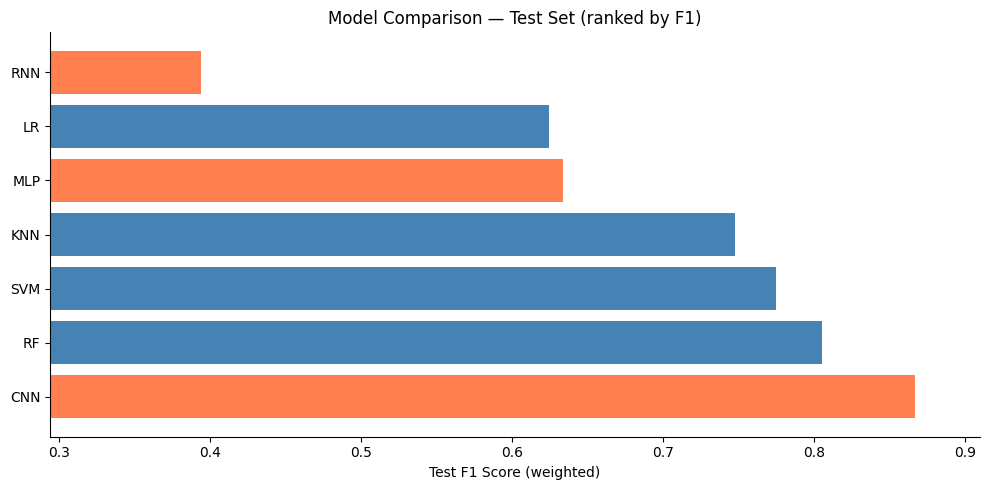

In [10]:
results_df = pd.DataFrame(results).T
results_df.index.name = 'Model'
results_df = results_df.sort_values('test_f1', ascending=False)

display_df = pd.DataFrame({
    'CV F1': results_df['cv_f1'].map('{:.4f}'.format) + ' ± ' + results_df['cv_f1_std'].map('{:.4f}'.format),
    'Test F1': results_df['test_f1'].map('{:.4f}'.format),
    'Test Acc': results_df['test_acc'].map('{:.4f}'.format),
    'Type': results_df['type'],
})
print(display_df.to_string())
print(f"\nBest model (by Test F1): {results_df.index[0]} ({results_df.iloc[0]['test_f1']:.4f})")

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['coral' if t == 'keras' else 'steelblue' for t in results_df['type']]
ax.barh(results_df.index, results_df['test_f1'], color=colors, capsize=4)
ax.set_xlabel('Test F1 Score (weighted)')
ax.set_title('Model Comparison — Test Set (ranked by F1)')
ax.set_xlim(left=max(0, results_df['test_f1'].min() - 0.1))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

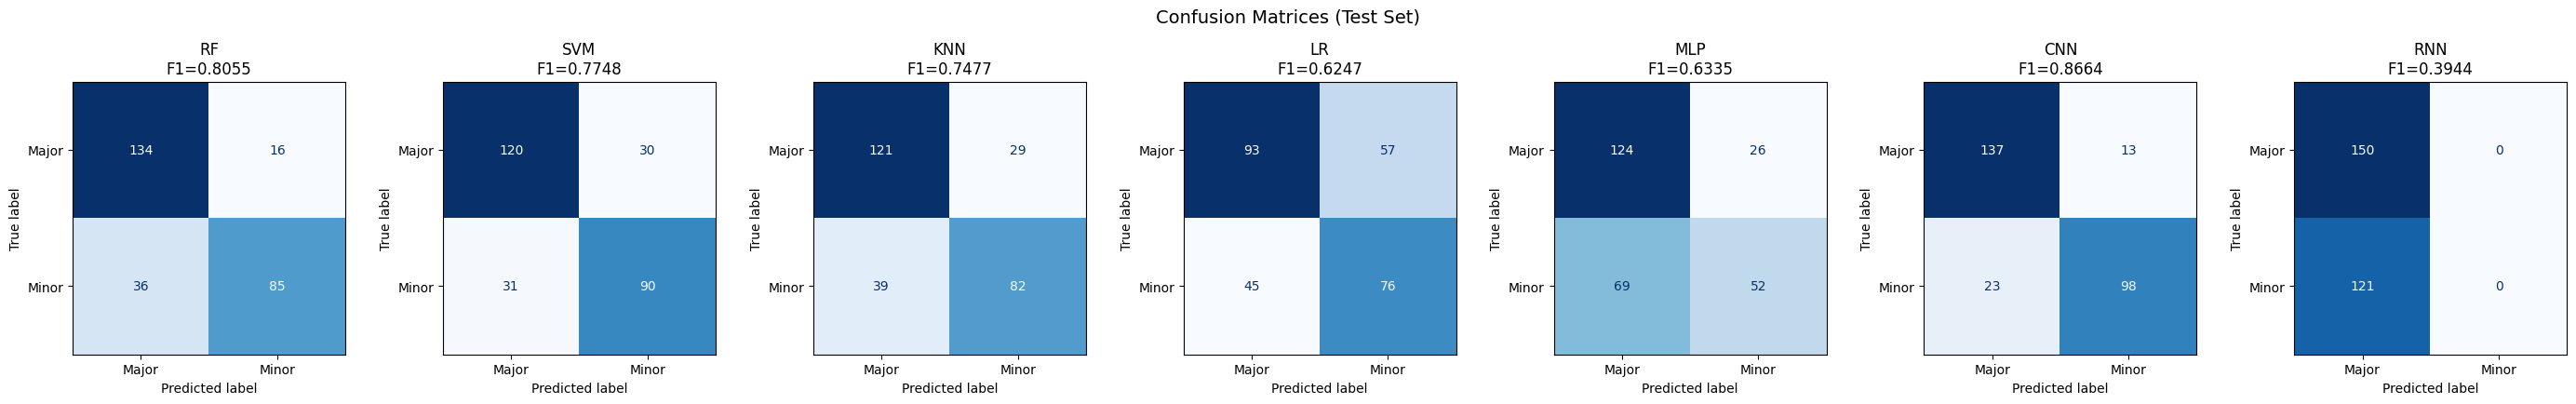

In [11]:
class_names = le.classes_
n_models = len(test_predictions)
fig, axes = plt.subplots(1, n_models, figsize=(4 * n_models, 4))

if n_models == 1:
    axes = [axes]

for ax, (name, preds) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
    f1_val = results[name]['test_f1']
    ax.set_title(f'{name}\nF1={f1_val:.4f}')

fig.suptitle('Confusion Matrices (Test Set)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

The CNN's strong performance likely comes from its ability to capture local spectral patterns in the audio features, things like the specific frequency relationships that define chord quality, which map naturally to convolutional filters. Random Forest benefits from being an ensemble method that combines many decision trees, making it robust to noise and capable of picking up on non-linear feature interactions without much tuning. \
The RNN's failure is somewhat expected here. RNNs are designed to model sequential dependencies over time, which is a great fit for tasks like melody recognition or speech, but chord classification from a fixed feature representation doesn't have that temporal structure to exploit. Without a meaningful sequence to learn from, the RNN likely struggled to find a useful gradient signal and defaulted to always predicting the dominant class.

In [13]:
MODEL_DIR = Path('../models')
MODEL_DIR.mkdir(exist_ok=True)

name_map = {'RF': 'rf', 'SVM': 'svm', 'KNN': 'knn', 'LR': 'lr'}

for model_name, info in results.items():
    model_dir = MODEL_DIR / model_name.lower()
    model_dir.mkdir(exist_ok=True)

    if info['type'] == 'sklearn':
        pipe = make_pipeline(StandardScaler(), get_sklearn_model(name_map[model_name]))
        pipe.fit(X_flat, y)
        joblib.dump(pipe, str(model_dir / 'model.pkl'))
        feature_type = 'features'

    elif model_name == 'MLP':
        m = build_mlp(X_flat.shape[1])
        m.fit(X_flat, y, epochs=120, batch_size=32, verbose=0,
              callbacks=default_keras_callbacks())
        m.save(str(model_dir / 'model.keras'))
        feature_type = 'features'

    elif model_name == 'CNN':
        m = build_cnn(X_cnn.shape[1:])
        m.fit(X_cnn, y, epochs=120, batch_size=32, verbose=0,
              callbacks=default_keras_callbacks())
        m.save(str(model_dir / 'model.keras'))
        feature_type = 'spectrogram'

    elif model_name == 'RNN':
        m = build_rnn(X_rnn.shape[1:])
        m.fit(X_rnn, y, epochs=120, batch_size=32, verbose=0,
              callbacks=default_keras_callbacks())
        m.save(str(model_dir / 'model.keras'))
        feature_type = 'spectrogram'

    config = {
        'model_name': model_name.lower(),
        'model_type': info['type'],
        'feature_type': feature_type,
        'labels': le.classes_.tolist(),
        'window_sec': WINDOW_SEC if feature_type == 'features' else None,
        'overlap': OVERLAP if feature_type == 'features' else None,
        'test_f1': round(info['test_f1'], 4),
        'test_acc': round(info['test_acc'], 4),
    }

    with open(model_dir / 'config.json', 'w') as f:
        json.dump(config, f, indent=2)

    joblib.dump(le, str(model_dir / 'label_encoder.pkl'))
    print(f"Saved {model_name} in {model_dir}/")

print(f"\nSaved {len(results)} models to {MODEL_DIR}/")

Saved RF in ../models/rf/
Saved SVM in ../models/svm/
Saved KNN in ../models/knn/
Saved LR in ../models/lr/
Saved MLP in ../models/mlp/
Saved CNN in ../models/cnn/
Saved RNN in ../models/rnn/

Saved 7 models to ../models/


In [14]:
!zip -r /models/models.zip /models

  adding: models/ (stored 0%)
  adding: models/rf/ (stored 0%)
  adding: models/rf/label_encoder.pkl (deflated 27%)
  adding: models/rf/model.pkl (deflated 72%)
  adding: models/rf/config.json (deflated 37%)
  adding: models/rnn/ (stored 0%)
  adding: models/rnn/model.keras (deflated 13%)
  adding: models/rnn/label_encoder.pkl (deflated 27%)
  adding: models/rnn/config.json (deflated 36%)
  adding: models/lr/ (stored 0%)
  adding: models/lr/label_encoder.pkl (deflated 27%)
  adding: models/lr/model.pkl (deflated 43%)
  adding: models/lr/config.json (deflated 36%)
  adding: models/svm/ (stored 0%)
  adding: models/svm/label_encoder.pkl (deflated 27%)
  adding: models/svm/model.pkl (deflated 70%)
  adding: models/svm/config.json (deflated 37%)
  adding: models/mlp/ (stored 0%)
  adding: models/mlp/model.keras (deflated 36%)
  adding: models/mlp/label_encoder.pkl (deflated 27%)
  adding: models/mlp/config.json (deflated 37%)
  adding: models/cnn/ (stored 0%)
  adding: models/cnn/model.ker

In [15]:
# Source - https://stackoverflow.com/a/52555629
# Posted by Shashank Mishra
# Retrieved 2026-02-12, License - CC BY-SA 4.0

from google.colab import files
files.download("/models/models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>